# Statistical Feature Analysis Project (Housing Dataset)


### 1. Load Dataset


In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

csv_path = "../csv/house_features.csv" if os.path.exists("../csv/house_features.csv") else "csv/house_features.csv"
df = pd.read_csv(csv_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())


Dataset Shape: (150, 6)

First 5 rows:
   house_id  area_sqft  bedrooms  age_years  distance_city_km  price_usd
0      1001       2324         3       27.9               4.3     306081
1      1002       2038         2       10.0               1.9     305692
2      1003       2391         4        0.5               9.8     400065
3      1004       2785         3        4.1               9.2     401298
4      1005       1995         3        4.5               4.4     360174


### 2. Descriptive Statistics, IQR, Skewness & Kurtosis


In [2]:
features = ["area_sqft", "bedrooms", "age_years", "distance_city_km", "price_usd"]

stats_rows = []
for col in features:
    s = df[col]
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    r_val, p_val = stats.pearsonr(df[col], df["price_usd"])
    
    stats_rows.append({
        "feature": col,
        "mean": round(s.mean(), 2),
        "median": round(s.median(), 2),
        "std_dev": round(s.std(), 2),
        "iqr": round(iqr, 2),
        "skewness": round(stats.skew(s), 2),
        "kurtosis": round(stats.kurtosis(s), 2),
        "corr_with_price": round(r_val, 3),
        "p_value": float(f"{p_val:.4e}")
    })

summary_df = pd.DataFrame(stats_rows)
print("Statistical Feature Summary:")
print(summary_df[["feature", "mean", "median", "std_dev", "iqr", "skewness", "kurtosis"]].to_string(index=False))


Statistical Feature Summary:
         feature      mean    median  std_dev       iqr  skewness  kurtosis
       area_sqft   2095.83   2086.00   495.26    519.25      1.08      3.91
        bedrooms      2.93      3.00     1.13      2.00      0.14     -0.60
       age_years      8.22      5.95     7.64      8.32      1.34      1.20
distance_city_km      7.94      6.70     5.74      6.05      1.39      2.43
       price_usd 326166.59 321650.00 83750.26 110372.25      0.62      2.43


### 3. Outlier Detection (Z-Score & IQR Method)


In [3]:
# 1. Z-Score Method (|Z| > 3)
z_scores = np.abs(stats.zscore(df["price_usd"]))
z_outliers = df[z_scores > 3.0][["house_id", "area_sqft", "price_usd"]]

# 2. IQR Method (1.5 * IQR rule)
q1, q3 = np.percentile(df["price_usd"], [25, 75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_outliers = df[(df["price_usd"] < lower_bound) | (df["price_usd"] > upper_bound)][["house_id", "area_sqft", "price_usd"]]

print(f"IQR Bounds for Price: Lower = ${lower_bound:,.0f} | Upper = ${upper_bound:,.0f}")
print("\nOutliers detected via Z-Score (|Z| > 3):")
print(z_outliers.to_string(index=False))
print("\nOutliers detected via IQR Rule:")
print(iqr_outliers.to_string(index=False))


IQR Bounds for Price: Lower = $104,329 | Upper = $545,818

Outliers detected via Z-Score (|Z| > 3):
 house_id  area_sqft  price_usd
     1011       4400     680000
     1046       4200     640000

Outliers detected via IQR Rule:
 house_id  area_sqft  price_usd
     1011       4400     680000
     1046       4200     640000
     1050       1307      96417
     1091       2144      95000


### 4. Feature Significance & Hypothesis Testing (Pearson r & T-Test)


In [4]:
print("Feature Correlation & P-Values with Target (price_usd):")
print(summary_df[["feature", "corr_with_price", "p_value"]].to_string(index=False))

# Hypothesis Test: Do houses with 4+ bedrooms have significantly higher prices?
high_bed = df[df["bedrooms"] >= 4]["price_usd"]
low_bed = df[df["bedrooms"] < 4]["price_usd"]

t_stat, p_val = stats.ttest_ind(high_bed, low_bed)
print("\nTwo-Sample T-Test (4+ Bedrooms vs <4 Bedrooms):")
print(f"T-Statistic: {t_stat:.4f} | P-Value: {p_val:.4e}")
if p_val < 0.05:
    print("Conclusion: Significant price difference between large and small bedroom houses (p < 0.05)")


Feature Correlation & P-Values with Target (price_usd):
         feature  corr_with_price      p_value
       area_sqft            0.885 4.049700e-51
        bedrooms            0.523 6.552600e-12
       age_years           -0.116 1.568600e-01
distance_city_km           -0.221 6.475400e-03
       price_usd            1.000 0.000000e+00

Two-Sample T-Test (4+ Bedrooms vs <4 Bedrooms):
T-Statistic: 5.5619 | P-Value: 1.2142e-07
Conclusion: Significant price difference between large and small bedroom houses (p < 0.05)


### 5. Feature Standardization (Z-Score Scaling vs Min-Max Scaling)


In [5]:
# Z-Score Standardization: (x - mean) / std
df["z_score_scaled"] = ((df["area_sqft"] - df["area_sqft"].mean()) / df["area_sqft"].std()).round(3)

# Min-Max Normalization: (x - min) / (max - min)
df["minmax_scaled"] = ((df["area_sqft"] - df["area_sqft"].min()) / (df["area_sqft"].max() - df["area_sqft"].min())).round(3)

print("Scaled Area Feature (First 5 rows):")
print(df[["area_sqft", "z_score_scaled", "minmax_scaled"]].head())


Scaled Area Feature (First 5 rows):
   area_sqft  z_score_scaled  minmax_scaled
0       2324           0.461          0.403
1       2038          -0.117          0.321
2       2391           0.596          0.423
3       2785           1.392          0.536
4       1995          -0.204          0.309


### 6. Visual Statistical Analysis (Distributions, Outliers & Correlations)


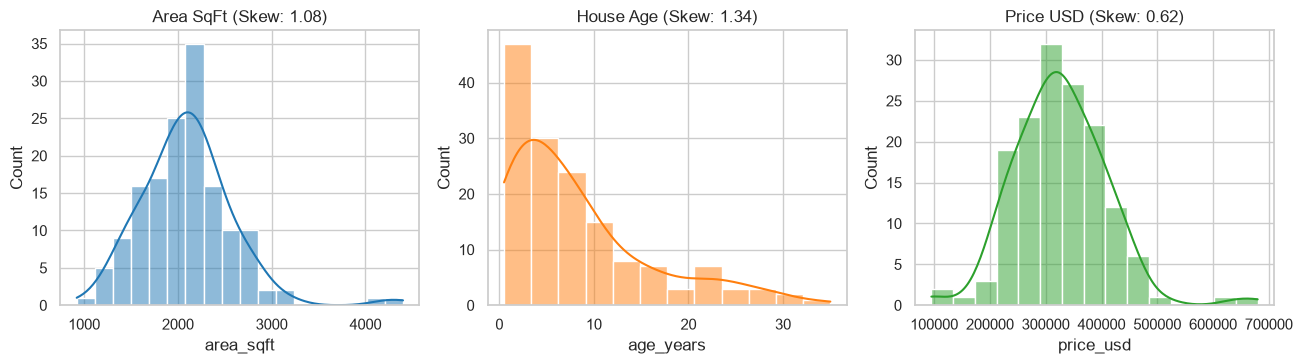

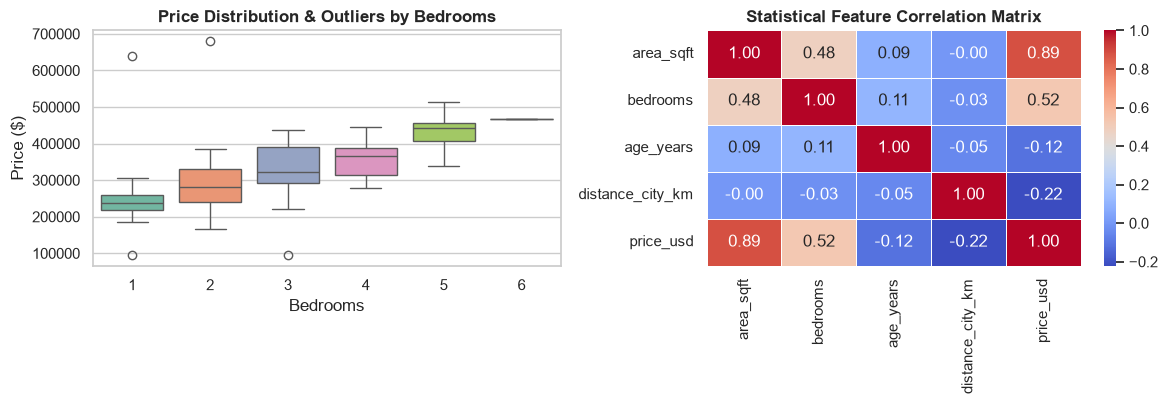

In [6]:
# 1. Feature Distributions & Skewness
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sns.histplot(df["area_sqft"], kde=True, color="#1f77b4", ax=axes[0])
axes[0].set_title(f"Area SqFt (Skew: {stats.skew(df['area_sqft']):.2f})")

sns.histplot(df["age_years"], kde=True, color="#ff7f0e", ax=axes[1])
axes[1].set_title(f"House Age (Skew: {stats.skew(df['age_years']):.2f})")

sns.histplot(df["price_usd"], kde=True, color="#2ca02c", ax=axes[2])
axes[2].set_title(f"Price USD (Skew: {stats.skew(df['price_usd']):.2f})")
plt.tight_layout()
plt.show()

# 2. Boxplot Outliers & Correlation Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=df, x="bedrooms", y="price_usd", hue="bedrooms", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Price Distribution & Outliers by Bedrooms", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Bedrooms")
axes[0].set_ylabel("Price ($)")

corr_matrix = df[features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, ax=axes[1])
axes[1].set_title("Statistical Feature Correlation Matrix", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 7. Export Statistical Summary to CSV


In [7]:
out_dir = "../csv" if os.path.exists("../csv") else "csv"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "statistical_features_summary.csv")

summary_df.to_csv(out_file, index=False)
print(f"Statistical summary saved to: {out_file}")


Statistical summary saved to: csv\statistical_features_summary.csv
